**Part A – Data Quality & Basic Insights**

In [ ]:
# Import Pandas
import pandas as pd

# Load the original CSV dataset
df = pd.read_csv("sales_raw.csv")

# Display first five rows
print("First Five Rows:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isna().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
print("Missing Values in Each Column:")
print(df.isna().sum())

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

Missing Values in Each Column:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Total Duplicate Rows:
1


In [3]:
# Preserve original dataset and create a working copy
df_clean = df.copy()

# Remove extra spaces and standardize text
df_clean['region'] = df_clean['region'].str.strip().str.title()
df_clean['category'] = df_clean['category'].str.strip().str.title()

# Display unique values after standardization
print("Regions:")
print(df_clean['region'].unique())

print("\nCategories:")
print(df_clean['category'].unique())

Regions:
['North' 'South' 'East' 'West' nan]

Categories:
['Food' 'Books' 'Stationery']


In [4]:
# Convert numeric columns for validation
df_clean['quantity'] = pd.to_numeric(
    df_clean['quantity'], errors='coerce'
)

df_clean['unit_price'] = pd.to_numeric(
    df_clean['unit_price'], errors='coerce'
)

# Identify invalid and missing values
print("Missing Quantity:")
print(df_clean['quantity'].isna().sum())

print("\nMissing or Invalid Unit Price:")
print(df_clean['unit_price'].isna().sum())

print("\nNon-positive Quantities:")
print((df_clean['quantity'] <= 0).sum())

print("\nNon-positive Prices:")
print((df_clean['unit_price'] <= 0).sum())

print("\nRows with Missing Region:")
print(df_clean['region'].isna().sum())

Missing Quantity:
1

Missing or Invalid Unit Price:
2

Non-positive Quantities:
1

Non-positive Prices:
0

Rows with Missing Region:
1


In [5]:
# Record original row count
rows_before = len(df_clean)

# 1. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Replace missing region with Unknown
df_clean['region'] = df_clean['region'].fillna('Unknown')

# 3. Remove rows with missing or invalid quantity and price
df_clean = df_clean.dropna(subset=['quantity', 'unit_price'])

# 4. Remove rows with zero or negative quantity and price
df_clean = df_clean[
    (df_clean['quantity'] > 0) &
    (df_clean['unit_price'] > 0)
]

# Record final row count
rows_after = len(df_clean)

# Display cleaning results
print("DATA CLEANING RESULTS")
print("---------------------")

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("\nMissing Values After Cleaning:")
print(df_clean.isna().sum())

print("\nDuplicate Rows After Cleaning:")
print(df_clean.duplicated().sum())

print("\nCleaned Dataset:")
display(df_clean)

DATA CLEANING RESULTS
---------------------
Rows before cleaning: 21
Rows after cleaning: 16
Rows removed: 5

Missing Values After Cleaning:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64

Duplicate Rows After Cleaning:
0

Cleaned Dataset:


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,Food,2.0,120.0
1,1002,10/1/2026,South,Books,1.0,250.0
2,1003,10/2/2026,North,Food,3.0,110.0
3,1004,10/2/2026,East,Stationery,4.0,50.0
4,1005,10/3/2026,South,Books,2.0,250.0
6,1007,10/4/2026,North,Stationery,3.0,60.0
7,1008,10/4/2026,East,Books,1.0,300.0
8,1009,10/5/2026,West,Food,5.0,90.0
11,1012,10/6/2026,North,Books,1.0,320.0
13,1014,invalid-date,West,Books,2.0,300.0


In [6]:
# Calculate revenue for each transaction
df_clean['revenue'] = df_clean['quantity'] * df_clean['unit_price']

# Display first five rows
print("Dataset with Revenue:")
display(df_clean.head())

Dataset with Revenue:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,10/1/2026,North,Food,2.0,120.0,240.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0


In [7]:
# Total revenue by category
category_summary = df_clean.groupby('category')['revenue'].sum()

print("Total Revenue by Category:")
display(category_summary)

# Total revenue by region
region_summary = df_clean.groupby('region')['revenue'].sum()

print("\nTotal Revenue by Region:")
display(region_summary)

Total Revenue by Category:


,revenue
category,
Books,2370.0
Food,1945.0
Stationery,10460.0



Total Revenue by Region:


,revenue
region,
East,740.0
North,11470.0
South,1035.0
Unknown,400.0
West,1130.0


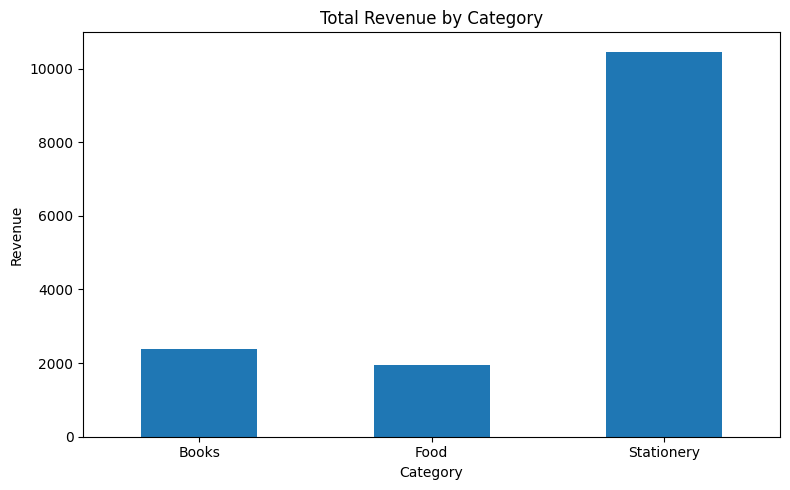

In [8]:
import matplotlib.pyplot as plt

# Create charts folder
import os
os.makedirs("charts", exist_ok=True)

# Revenue by Category
plt.figure(figsize=(8, 5))

category_summary.plot(kind='bar')

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("charts/chart_1.png")
plt.show()

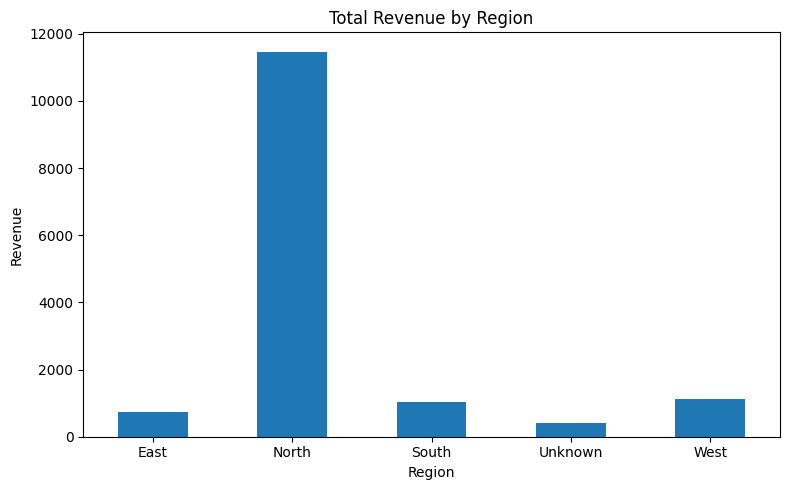

In [9]:
# Revenue by Region
plt.figure(figsize=(8, 5))

region_summary.plot(kind='bar')

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("charts/chart_2.png")
plt.show()

### Data Analysis Findings

**Finding 1 – Revenue by Category**

Stationery generated the highest revenue of 10,460, followed by Books with 2,370 and Food with 1,945. This shows that Stationery was the leading revenue-generating category in the cleaned dataset.

**Finding 2 – Revenue by Region**

North generated the highest regional revenue of 11,470, while East generated the lowest revenue of 740. This indicates that North was the strongest revenue-generating region in the cleaned dataset.

In [10]:
# Save cleaned dataset as a new CSV file
df_clean.to_csv("cleaned_sales.csv", index=False)

print("Cleaned dataset saved successfully!")

# Verify saved file
print("\nSaved File:")
print("cleaned_sales.csv")

print("\nFinal Dataset Shape:")
print(df_clean.shape)

# Display first five rows
display(df_clean.head())

Cleaned dataset saved successfully!

Saved File:
cleaned_sales.csv

Final Dataset Shape:
(16, 7)


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,10/1/2026,North,Food,2.0,120.0,240.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0


# Part B: CSV File Handling & Manipulation

In [11]:
# Load the cleaned CSV file
df_updated = pd.read_csv("cleaned_sales.csv")

# Display first five rows
print("First Five Rows of Cleaned Dataset:")
display(df_updated.head())

# Display dataset information
print("\nDataset Shape:")
print(df_updated.shape)

print("\nColumn Names:")
print(df_updated.columns.tolist())

First Five Rows of Cleaned Dataset:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,10/1/2026,North,Food,2.0,120.0,240.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0



Dataset Shape:
(16, 7)

Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue']


In [12]:
# Calculate tax amount (5% of revenue)
df_updated['tax_amount'] = df_updated['revenue'] * 0.05

# Display first five rows
print("Dataset with Tax Amount:")
display(df_updated.head())

Dataset with Tax Amount:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,Food,2.0,120.0,240.0,12.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0,12.5
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.5
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0,25.0


In [13]:
# Increase unit_price of Books items by 10%
df_updated.loc[
    df_updated['category'] == 'Books',
    'unit_price'
] *= 1.10

# Recalculate revenue
df_updated['revenue'] = (
    df_updated['quantity'] * df_updated['unit_price']
)

# Recalculate tax amount
df_updated['tax_amount'] = df_updated['revenue'] * 0.05

# Display updated Books records
print("Updated Books Records:")
display(df_updated[df_updated['category'] == 'Books'])

Updated Books Records:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75
4,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50
6,1008,10/4/2026,East,Books,1.0,330.0,330.0,16.50
8,1012,10/6/2026,North,Books,1.0,352.0,352.0,17.60
9,1014,invalid-date,West,Books,2.0,330.0,660.0,33.00
13,1018,10/9/2026,Unknown,Books,2.0,220.0,440.0,22.00


In [14]:
# Select transaction ID to remove
selected_id = 1018

# Find and remove the selected transaction
df_updated = df_updated[
    df_updated['transaction_id'] != selected_id
]

print("Removed Transaction ID:", selected_id)

print("\nUpdated Dataset Shape:")
print(df_updated.shape)

print("\nCheck if transaction still exists:")
print(df_updated[df_updated['transaction_id'] == selected_id])

Removed Transaction ID: 1018

Updated Dataset Shape:
(15, 8)

Check if transaction still exists:
Empty DataFrame
Columns: [transaction_id, sale_date, region, category, quantity, unit_price, revenue, tax_amount]
Index: []


In [15]:
# Create temporary review_status column
df_updated['review_status'] = 'Pending'

print("Dataset with Temporary Review Status:")
display(df_updated.head())

# Remove temporary review_status column
df_updated = df_updated.drop(columns=['review_status'])

print("\nDataset After Removing Review Status:")
print(df_updated.columns.tolist())

Dataset with Temporary Review Status:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,review_status
0,1001,10/1/2026,North,Food,2.0,120.0,240.0,12.00,Pending
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75,Pending
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50,Pending
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00,Pending
4,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50,Pending



Dataset After Removing Review Status:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']


In [16]:
# Save updated dataset
df_updated.to_csv("sales_updated.csv", index=False)

print("sales_updated.csv saved successfully!")

# Read the saved CSV again
df_verify = pd.read_csv("sales_updated.csv")

# Display first five rows
print("\nFirst Five Rows of Updated CSV:")
display(df_verify.head())

# Display final dataset shape
print("\nFinal Dataset Shape:")
print(df_verify.shape)

# Display final column names
print("\nFinal Column Names:")
print(df_verify.columns.tolist())

sales_updated.csv saved successfully!

First Five Rows of Updated CSV:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,Food,2.0,120.0,240.0,12.00
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00
4,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50



Final Dataset Shape:
(15, 8)

Final Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']


In [17]:
readme_content = """# Assignment 03 – Data Quality, Insights & CSV Operations

AI Engineering Bootcamp – Module 02

## Project Description
This project demonstrates data analysis and CSV manipulation using Python and Pandas.

## Part A – Data Quality & Basic Insights
- Loaded and inspected the sales dataset.
- Checked missing values and duplicate records.
- Standardized region and category names.
- Handled missing and invalid data.
- Calculated revenue.
- Generated grouped summaries.
- Created two visualizations.
- Saved cleaned_sales.csv.

## Part B – CSV File Handling & Manipulation
- Loaded cleaned_sales.csv.
- Added tax_amount equal to 5% of revenue.
- Increased Books prices by 10% using .loc[].
- Recalculated revenue and tax.
- Removed one selected transaction.
- Created and removed review_status.
- Saved sales_updated.csv.

## Files Included
- sales_raw.csv
- cleaned_sales.csv
- sales_updated.csv
- assignment_03.ipynb
- charts/

## Requirements
- Python 3
- Pandas
- Matplotlib
- Google Colab

## How to Run
1. Open the notebook in Google Colab.
2. Upload sales_raw.csv.
3. Run all notebook cells in order.

## GitHub Repository
Repository Link: PASTE YOUR GITHUB LINK HERE
"""

with open("README.md", "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!
